# Feature Importance Check, held out one feature and replace it with the training mean (remove the variability)

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))


import numpy as np
import torch
import torch.nn as nn
import json
from src.models.UNet_ConvLSTM_4En4De_pixel import UNetPhysDepth1
from src.utils.machine_learning.data_loader import (
    prepare_unet_dataloaders,
    prepare_unet_lstm_many_to_one_dataloaders,
)
from src.utils.machine_learning.evaluation import eval_r2_suite

In [2]:
# load the data
data_dir = "/scratch/jczhang/submeso_data_driven/src/data/mld_without_T/"
X = np.load(data_dir + "X.npy")
y = np.load(data_dir + "y.npy")
# create data_loader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader, val_loader, test_loader, meta = prepare_unet_dataloaders(
    X, y,
    batch_size=64,
    num_workers=8,
    seed=42,
    split_mode="time_ordered",            # "time_ordered" or "random"
    frac_train=0.8,
    frac_skip=0.0,
    frac_val=0.1,
    frac_test=0.1,
    normalize_x=True,
    normalize_y=True,
    shuffle_train=False,
    device=device,                    # for pin_memory logic
)

In [5]:
# create device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# load checkpoint
ckpt_path = "/scratch/jczhang/submeso_data_driven/check_point/cfg_25/best_unet_conv.pt"
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
# load model
model = UNetPhysDepth1(
    input_channels=7,
    head_channel=1,
    base=256,
    kernel_size=3,
    activation="SiLU",
    batch_norm="bn",
    dropout_2D=0.2,
    use_lstm=False,
    lstm_dropout=0.15,
).to(device)
model.load_state_dict(ckpt["model"])  # adjust if your key is different
model = model.to(device)
model.eval()

# evaluate normal test
test_metrics = eval_r2_suite(
    model=model,
    loader=test_loader,
    device=device,
    norm=meta.get("norm", None),   # adjust if your norm is stored elsewhere
    denorm_y=False,                # R2 is unchanged by denorm if applied to both
)

print("Pixel R2:", test_metrics["pixel_r2"])
print("Mean snapshot R2:", test_metrics["image_r2_mean"])
print("Median snapshot R2:", test_metrics["image_r2_median"])
print("Climate R2:", test_metrics["climate_r2"])
print("Number of test snapshots:", test_metrics["n_images"])

# save per-snapshot R2
snapshot_r2 = np.asarray(test_metrics["image_r2_list"], dtype=np.float64)
np.save("Without_T_r2_normal.npy", snapshot_r2)

print("Saved:", "test_snapshot_r2_normal.npy")
print("Shape:", snapshot_r2.shape)

Pixel R2: 0.4132562530985112
Mean snapshot R2: 0.3940230210969947
Median snapshot R2: 0.3976810350894808
Climate R2: 0.8995356009956138
Number of test snapshots: 1119
Saved: test_snapshot_r2_normal.npy
Shape: (1119,)


Shape: (1119,)
Mean R2: 0.3940230210969947
Median R2: 0.3976810350894808


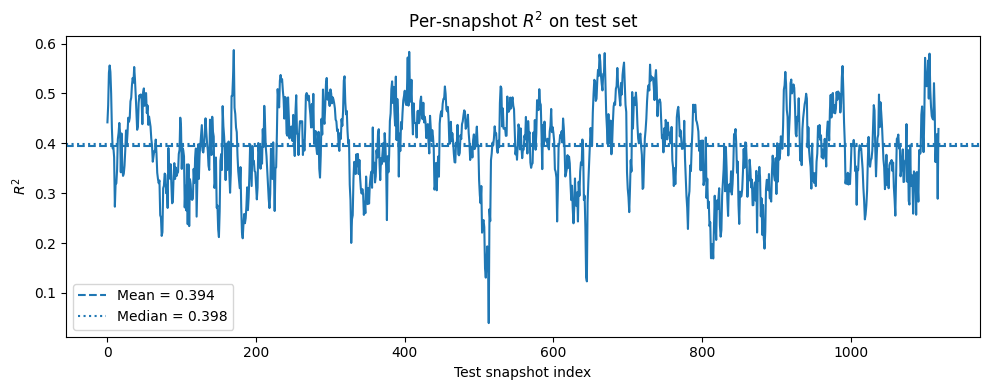

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# load saved snapshot R2
r2_path = "Without_T_r2_normal.npy"
r2 = np.load(r2_path)

print("Shape:", r2.shape)
print("Mean R2:", np.nanmean(r2))
print("Median R2:", np.nanmedian(r2))

# plot
plt.figure(figsize=(10, 4))
plt.plot(r2, linewidth=1.5)
plt.axhline(np.nanmean(r2), linestyle="--", linewidth=1.5, label=f"Mean = {np.nanmean(r2):.3f}")
plt.axhline(np.nanmedian(r2), linestyle=":", linewidth=1.5, label=f"Median = {np.nanmedian(r2):.3f}")

plt.xlabel("Test snapshot index")
plt.ylabel(r"$R^2$")
plt.title(r"Per-snapshot $R^2$ on test set")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
@torch.no_grad()
def eval_with_channel_mean_replacement(
    model, loader, device, channel_idx, x_mu, normalized_input=True
):
    model.eval()
    all_r2 = []

    x_mu = np.asarray(x_mu)

    # If loader gives normalized X, channel mean in normalized space is 0.
    # If loader gives physical/raw X, channel mean is x_mu[channel_idx].
    if normalized_input:
        fill_value = 0.0
    else:
        fill_value = float(x_mu.reshape(-1)[channel_idx])

    for xb, yb in loader:
        xb = xb.to(device).float()
        yb = yb.to(device).float()

        if yb.ndim == 3:
            yb = yb.unsqueeze(1)

        xb = xb.clone()
        xb[:, channel_idx, :, :] = fill_value

        pred = model(xb)
        if pred.ndim == 3:
            pred = pred.unsqueeze(1)

        B = yb.shape[0]
        yt = yb.reshape(B, -1).double()
        yp = pred.reshape(B, -1).double()

        yt_mean = yt.mean(dim=1, keepdim=True)
        ss_tot = ((yt - yt_mean) ** 2).sum(dim=1)
        ss_res = ((yt - yp) ** 2).sum(dim=1)

        r2 = 1.0 - ss_res / (ss_tot + 1e-12)
        r2 = torch.where(ss_tot <= 1e-12, torch.full_like(r2, float("nan")), r2)

        all_r2.extend(r2.cpu().tolist())

    return np.asarray(all_r2)

In [9]:
x_mu = meta["norm"]["X_mu"]

for c in range(7):
    r2_c = eval_with_channel_mean_replacement(
        model=model,
        loader=test_loader,
        device=device,
        channel_idx=c,
        x_mu=x_mu,
        normalized_input=True,  # True if dataloader returns normalized X
    )

    np.save(f"Without_T_r2_replace_ch{c}.npy", r2_c)
    print(c, np.nanmean(r2_c), np.nanmedian(r2_c))

0 0.3709655169701312 0.37529702906472007
1 0.3870158524410933 0.3868592792033023
2 0.3066580693427697 0.30974536198497893
3 0.3272818636265022 0.32318836623501523
4 0.3408561990062545 0.34339938131812897
5 0.3888167998166509 0.39186645743234627
6 0.20334076188264066 0.21850852864739057


IndexError: list index out of range

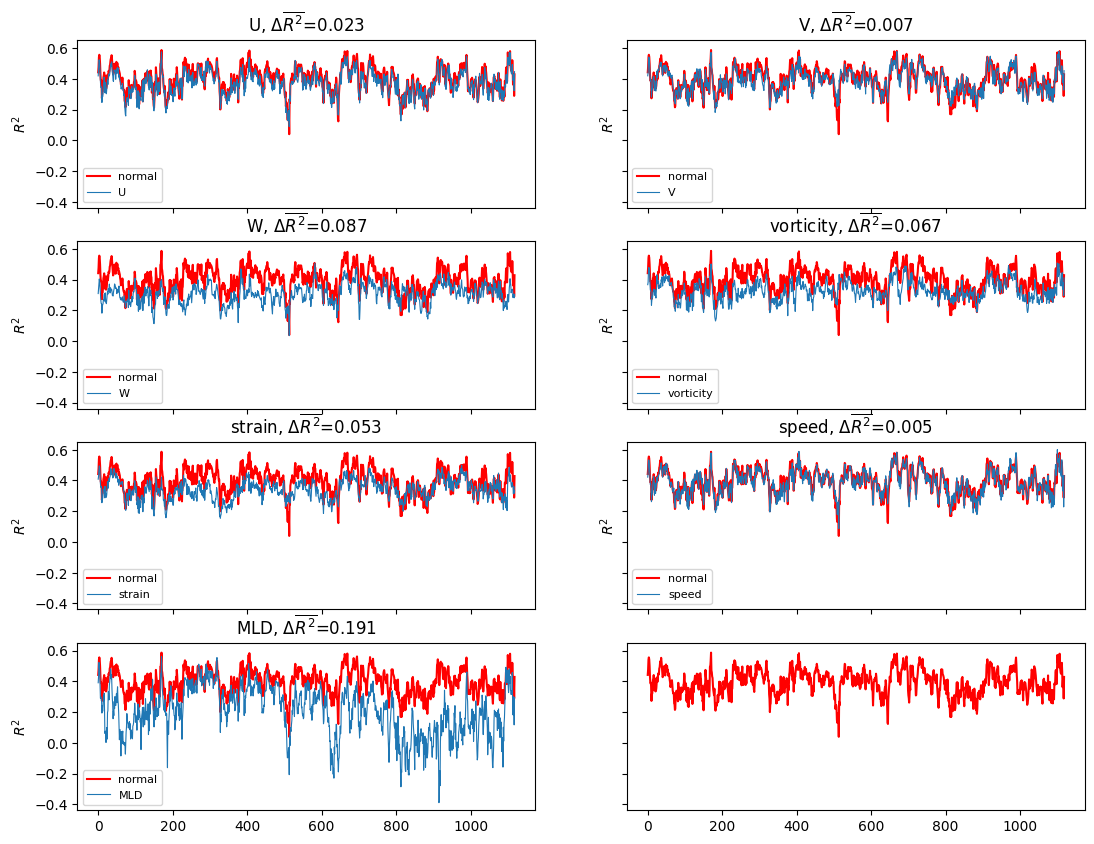

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharex=True, sharey=True)
axes = axes.ravel()

# -----------------------------
# load R2 files
# -----------------------------
r2_normal = np.load("Without_T_r2_normal.npy")

channel_names = [
    "U", "V", "W", "vorticity",
    "strain", "speed", "MLD"
]

r2_replace = []
for c in range(7):
    r2_c = np.load(f"Without_T_r2_replace_ch{c}.npy")
    r2_replace.append(r2_c)
    
for c, ax in enumerate(axes):
    ax.plot(r2_normal, color="red", linewidth=1.5, label="normal")
    ax.plot(r2_replace[c], linewidth=0.8, label=f"{channel_names[c]}")

    delta = np.nanmean(r2_normal) - np.nanmean(r2_replace[c])

    ax.set_title(
        f"{channel_names[c]}, "
        + rf"$\Delta \overline{{R^2}}$={delta:.3f}"
    )
    ax.set_ylabel(r"$R^2$")
    ax.legend(fontsize=8)
    
axes[-1].set_xlabel("Test snapshot index")
axes[-2].set_xlabel("Test snapshot index")

plt.tight_layout()
plt.show()

# KPPHBL is the most important feature
